# Adversarially Hardened Incremental Detector for AI-Generated Images

**Base paper:** Park, Na & Choi, *Performance Comparison and Visualization of AI-Generated-Image Detection Methods*, IEEE Access 12 (2024), DOI 10.1109/ACCESS.2024.3394250.

A ResNet-18 detector with growable specialist branches is trained against an adversary, then updated after deployment to catch a new family of fakes without retraining. Every result in the report comes from the outputs saved in this notebook.

| Module | What it does | Writes to Drive |
| --- | --- | --- |
| Setup + Quick start | Mount Drive, unzip data, import every module | — |
| 1 Data pipeline | Seven data splits, augmentation, loaders | `data_module.py` |
| 2 Backbone · 3 Branches + fusion | The detector architecture | `model_module.py` |
| 4 Adversaries | Three opponents: two failed (Path B, Path A), one final (PGD) | `generator_module.py`, `fig_degradation_stages.png` |
| 5 Training | Baseline, the adversarial loop, **failed runs (❌)**, the final hardening run | `train_utils.py`, `train_loop.py`, `baseline.pt`, `hardened.pt`, `replay_buffer.pt` |
| 6 Deployment + updates | Freeze, add one branch for a new fake family, forgetting fix | `deploy_module.py`, `hardened_updated*.pt`, `fig_lwf_tradeoff.png` |
| 7 Evaluation | Hardened vs baseline, growth ablation, sealed Pool C test, results summary | `nogrow.pt` |

**How to run.** Start every session with **Setup**, then **Quick start**; after that any cell can run on its own. The data subsets were sampled from Kaggle in a separate notebook and are loaded here from `aigi_data.zip`.

**Re-running is safe.** Training cells load their saved checkpoint instead of retraining unless `RETRAIN = True`, and failed experiments are skipped unless `RERUN_FAILED_EXPERIMENTS = True` (both set in Setup). The outputs shown under every cell are the recorded results of the original runs.

## Setup

Run first, every session. It mounts Drive, unzips the seven data splits into `/content/data` (wiped whenever the runtime restarts), puts the project folder on the import path, and picks the GPU.

Two switches control what slow cells do:
- `RETRAIN` — `False` loads saved checkpoints; `True` retrains and **overwrites** them.
- `RERUN_FAILED_EXPERIMENTS` — `False` skips the failed runs in Module 5 and shows their recorded logs instead.

In [2]:
# ---- run this first, every session ----
from google.colab import drive
drive.mount('/content/drive')
!rm -rf /content/data && mkdir -p /content/data
!unzip -qo "/content/drive/MyDrive/AI project/aigi_data.zip" -d /content/data

import os, sys, importlib, torch
sys.path.append('/content/drive/MyDrive/AI project')
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', dev)

# set True ONLY if you deliberately want to re-run the recorded failed experiments
RERUN_FAILED_EXPERIMENTS = False

# set True ONLY to retrain models and overwrite their saved checkpoints
RETRAIN = False

Mounted at /content/drive
device: cuda


## Quick start

Imports every class and function from the six module files on Drive and loads the baseline checkpoint. After Setup + Quick start, any later cell can run without running the cells above it.

In [3]:
# ---- quick start: run after Setup, instead of Run all ----
from data_module import get_loader, DST, build_transform, AIGIDataset
from model_module import Backbone, Branch, FusionHead, BranchBank, Detector
from generator_module import StagedGenerator, LiveGenerator, PGDAdversary
from train_utils import evaluate, full_eval, train_baseline
from train_loop import (ReplayBuffer, real_loader, gate_accuracy, spar,
                        adversarial_train, save_detector, load_detector)
from deploy_module import make_split, folder_loader, deploy, frozen_snapshot, incremental_update

P = '/content/drive/MyDrive/AI project'
CKPT = f'{P}/baseline.pt'
baseline = Detector(Backbone()).to(dev)
baseline.load_state_dict(torch.load(CKPT)); baseline.eval()
print('ready')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 183MB/s]


ready


# Module 1 — Data pipeline

Supplies every image the project uses, as seven disjoint splits, each with a `real/` and a `fake/` folder. All images were resized to 128×128 when sampled.

| Split | Real | Fake | Content; generator | Role |
| --- | --- | --- | --- | --- |
| `train` | 5,000 | 5,000 | LSUN cat, horse; ProGAN | The only training data |
| `val` | 400 | 400 | LSUN cat, horse; ProGAN | Early stopping; ProGAN accuracy |
| `val2` | 1,500 | 1,500 | LSUN cat, horse; ProGAN | Read by the evaluation gate (held out) |
| `poolB_sd` | 1,500 | 1,500 | ImageNet; Stable Diffusion | Unseen diffusion; Module 6 splits it 1,000 / 500 per class |
| `poolB_mj` | 500 | 500 | ImageNet; Midjourney | Unseen diffusion, never trained on |
| `poolC_stylegan2` | 1,000 | 1,000 | LSUN cat, horse; StyleGAN2 | Sealed final test (Module 7) |
| `poolC_biggan` | 1,000 | 1,000 | ImageNet; BigGAN | Sealed final test (Module 7) |

Sources: ForenSynths (Wang et al., CVPR 2020) and a GenImage subset.

### 1.1 Write `data_module.py`

- `RandomJPEG`, `RandomGaussianNoise` — augmentations: JPEG runs on the PIL image, noise on the tensor, both **before** normalisation.
- `build_transform(augment)` — flip, ±10° rotation, JPEG (quality 60–90), noise, ImageNet normalisation.
- `AIGIDataset(folder, label)` — one folder, one label (0 = real, 1 = fake).
- `get_loader(split)` — **real and fake together**, shuffled for `train`. Labels are float because the model uses `BCEWithLogitsLoss` on one logit.

⚠️ `get_loader` returns *both* classes. The adversarial loop needs real images only and uses `real_loader` (Module 5); using `get_loader` there was the label bug described in 5.5.

In [ ]:
%%writefile "/content/drive/MyDrive/AI project/data_module.py"
import io, os, random
import torch
from torch.utils.data import Dataset, DataLoader, ConcatDataset
from torchvision import transforms
from PIL import Image
from pathlib import Path

DST  = Path('/content/data')
SIZE = 128
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]


class RandomJPEG:
    def __init__(self, p=0.5, qmin=60, qmax=90):
        self.p, self.qmin, self.qmax = p, qmin, qmax
    def __call__(self, img):
        if random.random() > self.p:
            return img
        buf = io.BytesIO()
        img.save(buf, format='JPEG', quality=random.randint(self.qmin, self.qmax))
        buf.seek(0)
        return Image.open(buf).convert('RGB')


class RandomGaussianNoise:
    def __init__(self, p=0.5, sigma=0.02):
        self.p, self.sigma = p, sigma
    def __call__(self, t):
        if random.random() > self.p:
            return t
        return (t + torch.randn_like(t) * self.sigma).clamp(0, 1)


def build_transform(augment):
    if augment:
        return transforms.Compose([
            transforms.RandomHorizontalFlip(),
            transforms.RandomRotation(10),
            RandomJPEG(p=0.5),
            transforms.ToTensor(),
            RandomGaussianNoise(p=0.5),
            transforms.Normalize(MEAN, STD),
        ])
    return transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])


class AIGIDataset(Dataset):
    def __init__(self, folder, label, augment=False):
        self.files = sorted(Path(folder).glob('*.png'))
        self.label = label
        self.tf = build_transform(augment)
        if not self.files:
            raise ValueError(f'no images in {folder}')
    def __len__(self):
        return len(self.files)
    def __getitem__(self, i):
        img = Image.open(self.files[i]).convert('RGB')
        return self.tf(img), torch.tensor(self.label, dtype=torch.float32)


def get_loader(split, augment=False, batch_size=64, shuffle=None, workers=2):
    real = AIGIDataset(DST/split/'real', 0, augment)
    fake = AIGIDataset(DST/split/'fake', 1, augment)
    ds = ConcatDataset([real, fake])
    if shuffle is None:
        shuffle = (split == 'train')
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle,
                      num_workers=workers, pin_memory=True, drop_last=False)

Overwriting /content/drive/MyDrive/AI project/data_module.py


In [ ]:
# reload so this session uses the file just written
import data_module; importlib.reload(data_module)
from data_module import get_loader, AIGIDataset, DST, build_transform

### 1.2 Verify the splits

Expected: 5000/5000, 400/400, 1500/1500, 1500/1500, 500/500, 1000/1000, 1000/1000. Any `MISSING` means the unzip in Setup failed.

In [ ]:
import os
for split in ['train','val','val2','poolB_sd','poolB_mj','poolC_stylegan2','poolC_biggan']:
    for lab in ['real','fake']:
        p = f'/content/data/{split}/{lab}'
        print(split, lab, len(os.listdir(p)) if os.path.exists(p) else 'MISSING')

train real 5000
train fake 5000
val real 400
val fake 400
val2 real 1500
val2 fake 1500
poolB_sd real 1500
poolB_sd fake 1500
poolB_mj real 500
poolB_mj fake 500
poolC_stylegan2 real 1000
poolC_stylegan2 fake 1000
poolC_biggan real 1000
poolC_biggan fake 1000


### 1.3 Test one batch

Expected: `True Tesla T4`, a batch of shape `(64, 3, 128, 128)` in float32, and labels of shape `(64,)`. The mean is near 0 and the std a little above 1, because ImageNet normalisation constants plus the added noise do not exactly standardise these images.

In [ ]:
print(torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')
x, y = next(iter(get_loader('train', augment=True)))
print(x.shape, x.dtype, y.shape, y.dtype)
print('mean/std:', x.mean().item(), x.std().item())

True Tesla T4
torch.Size([64, 3, 128, 128]) torch.float32 torch.Size([64]) torch.float32
mean/std: -0.0008535468950867653 1.2741849422454834


# Module 2 — Backbone  ·  Module 3 — Branch bank and fusion head

Both modules live in one file, `model_module.py`. The detector is: **image → backbone → 512 numbers → every branch in parallel → concatenate → fusion head → one logit**.

**Module 2 — `Backbone`.** ResNet-18 pretrained on ImageNet, with its 1000-class output layer replaced by `nn.Identity()`, so a 128×128 image becomes a 512-d feature vector. ImageNet pretraining supplies general visual features; it has never seen a fake. `freeze()` locks the weights **and** puts BatchNorm in eval mode (disabling gradients alone lets BatchNorm statistics keep drifting). The `train()` override stops a later `model.train()` from silently un-freezing it.

**Module 3 — the growable head.**
- `Branch` — one specialist: 512 → 128 → 64, with dropout. Small on purpose, so an update stays cheap.
- `BranchBank` — the list of branches. `add_branch()` freezes every existing branch, then appends one new trainable branch: **exactly one branch is trainable at any time**.
- `FusionHead` — reads all branch outputs (64 per branch) and outputs one logit. `grow()` widens its input, copies the old weights and zeroes the new slots, so adding a branch leaves predictions unchanged until the new branch trains.
- `Detector` — wires everything together. `grow()` adds a branch and rebuilds the fusion head; `trainable_parameters()` returns only the newest branch plus the fusion head.

In [ ]:
%%writefile "/content/drive/MyDrive/AI project/model_module.py"
import torch
import torch.nn as nn
import torchvision


class Backbone(nn.Module):
    """ResNet-18 feature extractor. 128x128 image -> 512-d vector."""
    def __init__(self, pretrained=True):
        super().__init__()
        weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        net = torchvision.models.resnet18(weights=weights)
        net.fc = nn.Identity()
        self.net = net
        self.out_dim = 512
        self.frozen = False

    def forward(self, x):
        return self.net(x)

    def freeze(self):
        for p in self.net.parameters():
            p.requires_grad = False
        self.net.eval()
        self.frozen = True

    def train(self, mode=True):
        if self.frozen:
            return super().train(False)
        return super().train(mode)


class Branch(nn.Module):
    """One specialist head. 512-d feature -> 64 numbers."""
    def __init__(self, in_dim=512, hidden=128, out_dim=64, p_drop=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden),
            nn.ReLU(inplace=True),
            nn.Dropout(p_drop),
            nn.Linear(hidden, out_dim),
        )
        self.out_dim = out_dim
        self.frozen = False

    def forward(self, f):
        return self.net(f)

    def freeze(self):
        for p in self.parameters():
            p.requires_grad = False
        self.eval()
        self.frozen = True

    def train(self, mode=True):
        if self.frozen:
            return super().train(False)
        return super().train(mode)


class FusionHead(nn.Module):
    """Combines branch outputs into one logit. Resizable, weight-preserving."""
    def __init__(self, in_dim, hidden=64):
        super().__init__()
        self.in_dim = in_dim
        self.hidden = hidden
        self.fc1 = nn.Linear(in_dim, hidden)
        self.fc2 = nn.Linear(hidden, 1)

    def forward(self, z):
        return self.fc2(torch.relu(self.fc1(z))).squeeze(1)

    def grow(self, new_in_dim):
        old_fc1, old_in = self.fc1, self.in_dim
        new_fc1 = nn.Linear(new_in_dim, self.hidden)
        with torch.no_grad():
            new_fc1.weight.zero_()
            new_fc1.weight[:, :old_in] = old_fc1.weight
            new_fc1.bias.copy_(old_fc1.bias)
        self.fc1 = new_fc1.to(old_fc1.weight.device)
        self.in_dim = new_in_dim


class BranchBank(nn.Module):
    """Holds the growing list of specialists."""
    def __init__(self, in_dim=512, branch_out=64, cap=5):
        super().__init__()
        self.branches = nn.ModuleList([Branch(in_dim, out_dim=branch_out)])
        self.in_dim, self.branch_out, self.cap = in_dim, branch_out, cap

    def forward(self, f):
        return torch.cat([b(f) for b in self.branches], dim=1)

    @property
    def out_dim(self):
        return len(self.branches) * self.branch_out

    def can_grow(self):
        return len(self.branches) < self.cap

    def add_branch(self):
        if not self.can_grow():
            return False
        for b in self.branches:
            b.freeze()
        dev = next(self.parameters()).device
        self.branches.append(Branch(self.in_dim, out_dim=self.branch_out).to(dev))
        return True

    def trainable_branch(self):
        return self.branches[-1]


class Detector(nn.Module):
    """backbone -> branches -> fusion -> logit"""
    def __init__(self, backbone, cap=5, branch_out=64):
        super().__init__()
        self.backbone = backbone
        self.bank = BranchBank(backbone.out_dim, branch_out, cap)
        self.fusion = FusionHead(self.bank.out_dim)

    def forward(self, x):
        return self.fusion(self.bank(self.backbone(x)))

    def grow(self):
        if not self.bank.add_branch():
            return False
        self.fusion.grow(self.bank.out_dim)
        self.fusion.to(next(self.parameters()).device)
        return True

    def trainable_parameters(self):
        return list(self.bank.trainable_branch().parameters()) + list(self.fusion.parameters())

Overwriting /content/drive/MyDrive/AI project/model_module.py


In [ ]:
# reload so this session uses the file just written
import model_module; importlib.reload(model_module)
from model_module import Backbone, Branch, FusionHead, BranchBank, Detector

### 2.1 Module 2 test — shape, freeze, BatchNorm lock

Expected: feature shape `(64, 512)`; `trainable params: 0` after `freeze()`; `training mode: False` even after calling `train()`; and `bit-identical: True`. The last check matters most: identical outputs on two passes prove BatchNorm is not updating, so the backbone is genuinely frozen.

In [ ]:
bb = Backbone().to(dev)

# 1. shape
x, y = next(iter(get_loader('train')))
with torch.no_grad():
    f = bb(x.to(dev))
print('feature shape:', f.shape)        # expect (64, 512)

# 2. grads are off after freeze
bb.freeze()
print('trainable params:', sum(p.requires_grad for p in bb.parameters()))   # expect 0

# 3. the BatchNorm test — the important one
bb.train()                              # try to un-freeze
print('training mode:', bb.net.training)  # expect False
xb = x[:8].to(dev)
with torch.no_grad():
    a = bb(xb); b = bb(xb)
print('bit-identical:', torch.equal(a, b))   # expect True

feature shape: torch.Size([64, 512])
trainable params: 0
training mode: False
bit-identical: True


### 3.1 Module 3 test — growth must not change the output

Expected: fusion input 64 → 128 after one growth; `output unchanged after growth: True` (the weight copy works); exactly 1 trainable branch; 82,241 trainable parameters. That last number is the cost of training one branch plus the fusion head, under 1% of ResNet-18.

In [ ]:
det = Detector(Backbone()).to(dev)
x, y = next(iter(get_loader('train')))
xb = x[:16].to(dev)

det.eval()
with torch.no_grad():
    before = det(xb)
print('1 branch, output shape:', before.shape, '| fusion in_dim:', det.fusion.in_dim)

det.grow()
det.eval()
with torch.no_grad():
    after = det(xb)
print('2 branches, fusion in_dim:', det.fusion.in_dim)

print('output unchanged after growth:', torch.allclose(before, after, atol=1e-6))
print('trainable branches:', sum(not b.frozen for b in det.bank.branches))
print('trainable param count:', sum(p.numel() for p in det.trainable_parameters()))

1 branch, output shape: torch.Size([16]) | fusion in_dim: 64
2 branches, fusion in_dim: 128
output unchanged after growth: True
trainable branches: 1
trainable param count: 82241


*Confirm the file on Drive holds exactly the five classes, each once.*

In [ ]:
!grep "^class" "/content/drive/MyDrive/AI project/model_module.py"

class Backbone(nn.Module):
class Branch(nn.Module):
class FusionHead(nn.Module):
class BranchBank(nn.Module):
class Detector(nn.Module):


# Module 4 — Adversaries

*   List item
*   List item



The adversary supplies harder and harder fakes, so the detector cannot settle on one generator's fingerprint. Three were built; all share the interface the training loop calls: `sample(n, device)`, `advance_stage()`, `train_step(model)`.

| Adversary | How it makes fakes harder | Outcome |
| --- | --- | --- |
| `StagedGenerator` (Path B) | Same ProGAN fakes, progressively degraded | ❌ Failed — see 5.5 |
| `LiveGenerator` + `DCGenerator` (Path A) | A DCGAN trained live against the detector | ❌ Failed: mode collapse — see 5.5 |
| `PGDAdversary` (final) | Searches for small pixel changes that fool the current detector | ✅ Used for all reported results |

**Path B stages** (`StageDegrade`):

| Stage | JPEG quality | Downscale |
| --- | --- | --- |
| 1 | 75–95 | none |
| 2 | 40–60 | 0.7× and back up |
| 3 | 15–30 | 0.4× and back up |

**`PGDAdversary` (final).** For each batch it runs 3 steps of projected gradient descent against the *current* detector, nudging fakes toward "real" and real images toward "fake". Each pixel moves at most ε, and ε grows by stage (final schedule: 0.125, 0.25, 0.5, 1 per 255). Half of each batch is perturbed and half kept clean (`adv_frac = 0.5`), so clean accuracy is preserved. `sample_gate()` draws fakes from the held-out `val2` so the gate never reads training images. There is no network to train, so it cannot mode-collapse, and it always targets the detector's current weak points.

Fakes pass through the **same** `build_transform` pipeline as real images. When they did not, the detector separated the classes by preprocessing signature (failed run 1 in 5.5).

In [ ]:
%%writefile "/content/drive/MyDrive/AI project/generator_module.py"
import io, random, sys
import torch
import torch.nn as nn
from pathlib import Path
from PIL import Image

sys.path.append('/content/drive/MyDrive/AI project')
import torch.nn.functional as F
from data_module import build_transform, MEAN, STD


class StageDegrade:
    """Progressive corruption. Higher stage = harder to detect."""
    def __init__(self, stage=1):
        self.set_stage(stage)

    def set_stage(self, stage):
        self.stage = stage
        self.q  = {1: (75, 95), 2: (40, 60), 3: (15, 30)}[stage]
        self.sc = {1: 1.0,      2: 0.7,      3: 0.4}[stage]

    def __call__(self, img):
        if self.sc < 1.0:
            w, h = img.size
            small = img.resize((int(w*self.sc), int(h*self.sc)), Image.BICUBIC)
            img = small.resize((w, h), Image.BICUBIC)
        buf = io.BytesIO()
        img.save(buf, format='JPEG', quality=random.randint(*self.q))
        buf.seek(0)
        return Image.open(buf).convert('RGB')


class StagedGenerator:
    """Serves fakes of increasing difficulty, through the SAME augmentation
    pipeline the real images use — otherwise the detector separates the two
    classes by their preprocessing signature instead of by content."""
    def __init__(self, fake_dir, augment=True):
        self.files = sorted(Path(fake_dir).glob('*.png'))
        self.degrade = StageDegrade(1)
        self.tf = build_transform(augment)      # identical to the real loader
        self.max_stage = 3

    def sample(self, n, device='cuda'):
        picks = random.sample(self.files, min(n, len(self.files)))
        imgs = []
        for p in picks:
            img = Image.open(p).convert('RGB')
            img = self.degrade(img)             # stage-specific corruption
            imgs.append(self.tf(img))           # then the shared pipeline
        return torch.stack(imgs).to(device)

    def advance_stage(self):
        if self.degrade.stage >= self.max_stage:
            return False
        self.degrade.set_stage(self.degrade.stage + 1)
        return True

    def train_step(self, *a, **k):
        return None


class DCGenerator(nn.Module):
    """noise -> 128x128x3 image"""
    def __init__(self, z_dim=100):
        super().__init__()
        self.z_dim = z_dim
        self.net = nn.Sequential(
            nn.ConvTranspose2d(z_dim, 512, 4, 1, 0, bias=False),
            nn.BatchNorm2d(512), nn.ReLU(True),
            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256), nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(True),
            nn.ConvTranspose2d(64, 32, 4, 2, 1, bias=False),
            nn.BatchNorm2d(32), nn.ReLU(True),
            nn.ConvTranspose2d(32, 3, 4, 2, 1, bias=False),
            nn.Tanh(),
        )

    def forward(self, z):
        return self.net(z.view(-1, self.z_dim, 1, 1))

    def sample(self, n, device='cuda'):
        z = torch.randn(n, self.z_dim, device=device)
        return self(z)

    def advance_stage(self):
        return False

class LiveGenerator:
    """Path A. Trains against the detector; output mixed with real ProGAN fakes."""
    def __init__(self, pool_dir, z_dim=100, lr=2e-4, mix=0.5, device='cuda'):
        self.G = DCGenerator(z_dim).to(device)
        self.opt = torch.optim.Adam(self.G.parameters(), lr=lr, betas=(0.5, 0.999))
        self.pool = sorted(Path(pool_dir).glob('*.png'))
        self.tf = build_transform(False)          # no augmentation, matches reals
        self.mix, self.device = mix, device
        self.mean = torch.tensor(MEAN).view(1, 3, 1, 1).to(device)
        self.std  = torch.tensor(STD).view(1, 3, 1, 1).to(device)

    def _generate(self, n):
        x = (self.G.sample(n, self.device) + 1) / 2   # tanh [-1,1] -> [0,1]
        return (x - self.mean) / self.std              # same normalisation as reals

    def sample(self, n, device='cuda'):
        n_live = int(n * self.mix)
        with torch.no_grad():
            live = self._generate(n_live)
        picks = random.sample(self.pool, n - n_live)
        pool = torch.stack([self.tf(Image.open(p).convert('RGB')) for p in picks]).to(device)
        return torch.cat([live, pool])

    def train_step(self, detector, n=32):
        """Update the generator to make the detector say 'real'."""
        detector.eval()
        self.G.train()
        self.opt.zero_grad()
        logits = detector(self._generate(n))
        loss = F.binary_cross_entropy_with_logits(logits, torch.zeros_like(logits))
        loss.backward()
        self.opt.step()
        detector.train()
        return loss.item()

    def advance_stage(self):
        return False


class PGDAdversary:
    """Adversarial search. Each batch, it perturbs ProGAN fakes toward 'real'
    and real images toward 'fake', searching (with PGD) for the change that
    best fools the CURRENT detector. The change is capped at eps per pixel,
    and eps grows with the stage. There's no network to train, so it can't
    mode-collapse, and it always targets the detector's current weak spots."""
    def __init__(self, fake_dir, gate_fake_dir, eps_schedule=(2, 4, 6, 8),
                 steps=3, adv_frac=0.5, augment=True, device='cuda'):
        self.files      = sorted(Path(fake_dir).glob('*.png'))
        self.gate_files = sorted(Path(gate_fake_dir).glob('*.png'))
        self.tf         = build_transform(augment)   # same pipeline as training reals
        self.gate_tf    = build_transform(False)     # same pipeline as gate reals
        self.eps_list   = [e / 255 for e in eps_schedule]
        self.stage, self.max_stage = 1, len(self.eps_list)
        self.steps, self.adv_frac, self.device = steps, adv_frac, device
        self.mean = torch.tensor(MEAN).view(1, 3, 1, 1).to(device)
        self.std  = torch.tensor(STD).view(1, 3, 1, 1).to(device)
        self.model = None

    @property
    def eps(self):
        return self.eps_list[self.stage - 1]

    def attach(self, model):
        self.model = model

    def _load(self, files, tf, n, device):
        picks = random.sample(files, min(n, len(files)))
        return torch.stack([tf(Image.open(p).convert('RGB')) for p in picks]).to(device)

    def _pgd(self, x, target):
        """Search for a perturbation that makes the detector say `target`
        (0 = real, 1 = fake). Works in pixel space, so eps means pixels."""
        m = self.model
        was_training = m.training
        m.eval()                                   # don't disturb BatchNorm stats
        eps, alpha = self.eps, 2.5 * self.eps / self.steps
        pix = (x * self.std + self.mean).detach()
        y = torch.full((x.size(0),), float(target), device=x.device)
        delta = torch.empty_like(pix).uniform_(-eps, eps)
        with torch.enable_grad():                  # the gate runs under no_grad
            for _ in range(self.steps):
                delta.requires_grad_(True)
                adv = ((pix + delta).clamp(0, 1) - self.mean) / self.std
                loss = F.binary_cross_entropy_with_logits(m(adv), y)
                grad, = torch.autograd.grad(loss, delta)
                delta = (delta - alpha * grad.sign()).clamp(-eps, eps).detach()
        m.train(was_training)
        return (((pix + delta).clamp(0, 1) - self.mean) / self.std).detach()

    def _mix(self, x, target):
        """Perturb a fraction of the batch and keep the rest clean, so the
        detector keeps its clean-image accuracy too."""
        k = int(len(x) * self.adv_frac)
        if self.model is None or k == 0:
            return x
        return torch.cat([self._pgd(x[:k], target), x[k:]])

    def sample(self, n, device='cuda'):            # training fakes
        return self._mix(self._load(self.files, self.tf, n, device), target=0)

    def sample_gate(self, n, device='cuda'):       # held-out fakes for the gate
        return self._mix(self._load(self.gate_files, self.gate_tf, n, device), target=0)

    def perturb_real(self, xr):                    # reals pushed toward 'fake'
        return self._mix(xr, target=1)

    def advance_stage(self):
        if self.stage >= self.max_stage:
            return False
        self.stage += 1
        return True

    def train_step(self, *a, **k):
        return None

Overwriting /content/drive/MyDrive/AI project/generator_module.py


In [ ]:
# reload so this session uses the file just written
import generator_module; importlib.reload(generator_module)
from generator_module import StagedGenerator, DCGenerator, LiveGenerator, PGDAdversary

### 4.1 Test: Path B stages and DCGAN output shape

Three *different* random fakes, one per stage, plus shape checks. Expected: batch `(8, 3, 128, 128)`, `advance: True → stage 2`, DCGAN sample `(4, 3, 128, 128)`.

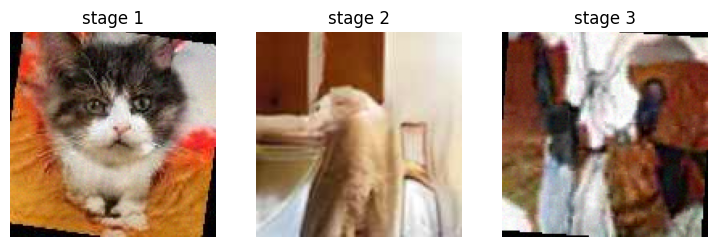

batch shape: torch.Size([8, 3, 128, 128])
advance: True → stage 2
DCGAN sample: torch.Size([4, 3, 128, 128])


In [ ]:
import matplotlib.pyplot as plt

gen = StagedGenerator('/content/data/train/fake')

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for s in [1, 2, 3]:
    gen.degrade.set_stage(s)
    img = gen.sample(1, dev)[0].cpu()
    img = img * torch.tensor([0.229,0.224,0.225]).view(3,1,1) + torch.tensor([0.485,0.456,0.406]).view(3,1,1)
    axes[s-1].imshow(img.permute(1,2,0).clamp(0,1)); axes[s-1].set_title(f'stage {s}'); axes[s-1].axis('off')
plt.show()

gen.degrade.set_stage(1)
print('batch shape:', gen.sample(8, dev).shape)
print('advance:', gen.advance_stage(), '→ stage', gen.degrade.stage)

g = DCGenerator().to(dev)
print('DCGAN sample:', g.sample(4, dev).shape)

### 4.2 Degradation on one image (report figure)

The same fake at each stage, saved as `fig_degradation_stages.png`. The cell resets the generator to stage 1 afterwards because `gen.degrade` is stateful.

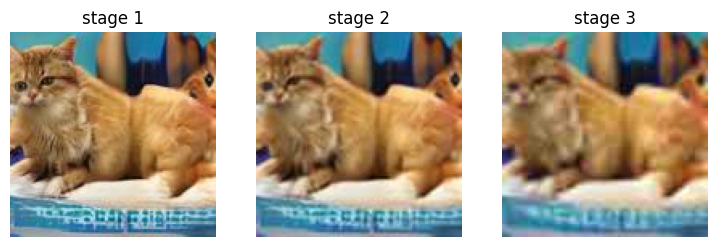

In [ ]:
from PIL import Image
from pathlib import Path

p = sorted(Path('/content/data/train/fake').glob('*.png'))[0]
orig = Image.open(p).convert('RGB')

fig, axes = plt.subplots(1, 3, figsize=(9,3))
for s in [1,2,3]:
    gen.degrade.set_stage(s)
    axes[s-1].imshow(gen.degrade(orig)); axes[s-1].set_title(f'stage {s}'); axes[s-1].axis('off')
plt.savefig('/content/drive/MyDrive/AI project/fig_degradation_stages.png', dpi=150, bbox_inches='tight')
plt.show()

gen.degrade.set_stage(1)   # reset, so later cells start clean

# Module 5 — Training

1. **5.1–5.3:** training utilities, the baseline (control model) and its numbers.
2. **5.4:** `train_loop.py`, the adversarial training loop in its final, corrected form.
3. **5.5:** the experiment history: five failed runs, each marked ❌ with what went wrong and how it was fixed.
4. **5.6:** calibrating the attack budget from the baseline's robustness.
5. **5.7:** the final hardening run ✅ that produced `hardened.pt`.

### 5.1 Training utilities — `train_utils.py`

- `evaluate(model, loader)` — accuracy and mean loss.
- `train_baseline(...)` — conventional training: backbone learning rate 1e-4, branch and fusion 1e-3 (pretrained features need gentle updates), `BCEWithLogitsLoss`, checkpoint at the best validation accuracy, early stopping after 3 epochs without improvement.
- `full_eval(model, loader, tag=...)` — accuracy, real-class accuracy, fake-class accuracy and AUROC. AUROC is the headline metric because it does not depend on the 0.5 threshold.

In [ ]:
%%writefile "/content/drive/MyDrive/AI project/train_utils.py"
import torch
import torch.nn as nn


@torch.no_grad()
def evaluate(model, loader, device='cuda'):
    """Returns (accuracy, mean loss) on a loader."""
    model.eval()
    crit = nn.BCEWithLogitsLoss()
    correct = total = 0
    loss_sum = 0.0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss_sum += crit(logits, y).item() * y.size(0)
        preds = (torch.sigmoid(logits) > 0.5).float()
        correct += (preds == y).sum().item()
        total += y.size(0)
    return correct / total, loss_sum / total


def train_baseline(model, train_loader, val_loader, epochs=8,
                   lr_head=1e-3, lr_backbone=1e-4, device='cuda',
                   patience=3, ckpt_path=None, verbose=True):
    """Conventional training. Returns (history, best_val_acc)."""
    crit = nn.BCEWithLogitsLoss()
    opt = torch.optim.Adam([
        {'params': model.backbone.parameters(),                      'lr': lr_backbone},
        {'params': model.bank.trainable_branch().parameters(),       'lr': lr_head},
        {'params': model.fusion.parameters(),                        'lr': lr_head},
    ])

    history, best_acc, bad_epochs = [], 0.0, 0

    for ep in range(1, epochs + 1):
        model.train()
        run_loss = seen = 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = crit(model(x), y)
            loss.backward()
            opt.step()
            run_loss += loss.item() * y.size(0)
            seen += y.size(0)

        tr_loss = run_loss / seen
        val_acc, val_loss = evaluate(model, val_loader, device)
        history.append({'epoch': ep, 'train_loss': tr_loss,
                        'val_acc': val_acc, 'val_loss': val_loss})
        if verbose:
            print(f'epoch {ep:2d} | train loss {tr_loss:.4f} | '
                  f'val loss {val_loss:.4f} | val acc {val_acc:.4f}')

        if val_acc > best_acc:
            best_acc, bad_epochs = val_acc, 0
            if ckpt_path:
                torch.save(model.state_dict(), ckpt_path)
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                if verbose:
                    print(f'early stop at epoch {ep} (best val acc {best_acc:.4f})')
                break

    return history, best_acc
def full_eval(model, loader, device='cuda', tag=''):
    """acc, per-class acc, AUROC. Pass a loader, not a pool name."""
    from sklearn.metrics import roc_auc_score
    model.eval()
    scores, labels = [], []
    with torch.no_grad():
        for x, y in loader:
            scores.append(torch.sigmoid(model(x.to(device))).cpu())
            labels.append(y)
    s, l = torch.cat(scores), torch.cat(labels)
    preds = (s > 0.5).float()
    out = {
        'acc':   (preds == l).float().mean().item(),
        'real':  (preds[l == 0] == 0).float().mean().item(),
        'fake':  (preds[l == 1] == 1).float().mean().item(),
        'auroc': roc_auc_score(l.numpy(), s.numpy()),
    }
    if tag:
        print(f"{tag}: acc {out['acc']:.4f} | real {out['real']:.4f} | "
              f"fake {out['fake']:.4f} | AUROC {out['auroc']:.4f}")
    return out

Overwriting /content/drive/MyDrive/AI project/train_utils.py


In [ ]:
# reload so this session uses the file just written
import train_utils; importlib.reload(train_utils)
from train_utils import evaluate, train_baseline, full_eval

### 5.2 Baseline (control model)

One branch, conventional training on `train`, 8 epochs. Every later claim is measured against this model. If `baseline.pt` exists it is loaded rather than retrained, and the best epoch (epoch 7, val accuracy 0.861) is always used, not the last.

In [ ]:
CKPT = '/content/drive/MyDrive/AI project/baseline.pt'
baseline = Detector(Backbone()).to(dev)

if os.path.exists(CKPT):
    print('baseline.pt exists, loading it (delete the file to retrain)')
else:
    hist, best = train_baseline(
        baseline,
        get_loader('train', augment=True, batch_size=64),
        get_loader('val',   augment=False, batch_size=64),
        epochs=8, ckpt_path=CKPT)

baseline.load_state_dict(torch.load(CKPT))   # always use the best epoch
baseline.eval()
print('baseline ready')

baseline.pt exists, loading it (delete the file to retrain)
baseline ready


### 5.3 Baseline numbers

**Result:** strong on ProGAN (AUROC 0.934), blind to diffusion. On both diffusion pools about 90% of real images are labelled correctly but fewer than 10% of fakes are caught. AUROC below 0.5 means the baseline ranks diffusion fakes as *more* real-looking than real photographs: a systematic failure, reproducing the base paper's finding that detectors do not transfer across generator families.

In [ ]:
for pool in ['val', 'poolB_sd', 'poolB_mj']:
    full_eval(baseline, get_loader(pool, augment=False), dev, tag=pool)

val: acc 0.8612 | real 0.8600 | fake 0.8625 | AUROC 0.9339
poolB_sd: acc 0.4877 | real 0.9007 | fake 0.0747 | AUROC 0.4612
poolB_mj: acc 0.4980 | real 0.8960 | fake 0.1000 | AUROC 0.4803


### 5.4 The adversarial loop — `train_loop.py`

Training runs in **rounds**. Each round:
1. **Sparring** (`spar`) — the detector trains on real images against the adversary's current fakes. Only the newest branch, the fusion head and (in this phase) the backbone update; a sample of fakes goes into the replay buffer.
2. **Gate** (`gate_accuracy`) — detector accuracy on **held-out** `val2` reals versus the adversary's held-out fakes.
3. **Decision** — gate below 0.70 and room to grow: freeze all branches, add one, train it (`train_new_branch`) on current fakes plus 25% replayed old fakes. Otherwise the adversary moves to its next stage.
4. **Stop** when the branch cap (5) is full and the gate has been quiet for two rounds, or after the round limit.

Also in the file: `real_loader` (**real images only**, the fix for the label bug), `ReplayBuffer` (float16, saved with the model), `save_detector` / `load_detector` (store the branch count, so a grown model can be rebuilt, including one above the default cap).

In [ ]:
%%writefile "/content/drive/MyDrive/AI project/train_loop.py"
import sys
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

sys.path.append('/content/drive/MyDrive/AI project')
from data_module import AIGIDataset, DST
from model_module import Backbone, Detector


def real_loader(split, augment=False, batch_size=32, workers=2):
    """REAL images only. get_loader() mixes real AND fake images, so it must
    never be used as the loop's 'real' side."""
    ds = AIGIDataset(DST / split / 'real', 0, augment)
    return DataLoader(ds, batch_size=batch_size, shuffle=True,
                      num_workers=workers, pin_memory=True, drop_last=True)


class ReplayBuffer:
    """Stores fakes from past rounds, tagged by round. Lives past training."""
    def __init__(self, cap_per_round=300):
        self.cap = cap_per_round
        self.store = {}                       # round -> float16 tensor (N,3,128,128)

    def add(self, batch, round_id):
        b = batch.detach().cpu().half()       # float16 halves RAM
        cur = self.store.get(round_id)
        cur = b if cur is None else torch.cat([cur, b])
        if len(cur) > self.cap:
            cur = cur[torch.randperm(len(cur))[:self.cap]]
        self.store[round_id] = cur

    def sample(self, n, exclude_round=None, device='cuda'):
        pools = [v for k, v in self.store.items() if k != exclude_round]
        if not pools:
            return None
        allf = torch.cat(pools)
        idx = torch.randperm(len(allf))[:min(n, len(allf))]
        return allf[idx].float().to(device)

    def __len__(self):
        return sum(len(v) for v in self.store.values())

    def state_dict(self):
        return {'cap': self.cap, 'store': self.store}

    def load_state_dict(self, d):
        self.cap, self.store = d['cap'], d['store']


def _next(it, loader):
    try:
        return next(it), it
    except StopIteration:
        it = iter(loader)
        return next(it), it


def _perturb_real(generator, xr):
    """Nudge reals toward 'fake' if the adversary supports it (PGD does)."""
    f = getattr(generator, 'perturb_real', None)
    return f(xr) if f is not None else xr


def _stage(generator):
    s = getattr(generator, 'stage', None)
    if s is None and hasattr(generator, 'degrade'):
        s = generator.degrade.stage
    return s


@torch.no_grad()
def gate_accuracy(model, generator, reals, n_batches=12, device='cuda'):
    """Accuracy on held-out reals vs the adversary's CURRENT fakes.
    This is the signal the gate reads."""
    model.eval()
    sample = getattr(generator, 'sample_gate', generator.sample)
    correct = total = 0
    it = iter(reals)
    for _ in range(n_batches):
        (xr, _), it = _next(it, reals)
        xr = _perturb_real(generator, xr.to(device))
        xf = sample(xr.size(0), device)
        x = torch.cat([xr, xf])
        y = torch.cat([torch.zeros(len(xr)), torch.ones(len(xf))]).to(device)
        preds = (torch.sigmoid(model(x)) > 0.5).float()
        correct += (preds == y).sum().item()
        total += y.numel()
    return correct / total


def spar(model, generator, reals, opt, steps, buffer, round_id,
         device='cuda', store_every=20):
    """Phase A: train the detector against the adversary's current fakes."""
    crit = nn.BCEWithLogitsLoss()
    it = iter(reals)
    run_loss = 0.0
    for i in range(steps):
        (xr, _), it = _next(it, reals)
        xr = _perturb_real(generator, xr.to(device))
        xf = generator.sample(xr.size(0), device)

        model.train()
        x = torch.cat([xr, xf])
        y = torch.cat([torch.zeros(len(xr)), torch.ones(len(xf))]).to(device)
        opt.zero_grad()
        loss = crit(model(x), y)
        loss.backward()
        opt.step()
        run_loss += loss.item()

        generator.train_step(model)             # no-op for PGD and Path B
        if i % store_every == 0:
            buffer.add(xf, round_id)
    return run_loss / steps


def train_new_branch(model, generator, reals, buffer, round_id,
                     steps=300, lr=1e-3, device='cuda', replay_frac=0.25):
    """After growth: train ONLY the new branch + fusion, on current + replayed fakes."""
    crit = nn.BCEWithLogitsLoss()
    opt = torch.optim.Adam(model.trainable_parameters(), lr=lr)
    it = iter(reals)
    for _ in range(steps):
        (xr, _), it = _next(it, reals)
        xr = _perturb_real(generator, xr.to(device))
        n = xr.size(0)
        n_replay = int(n * replay_frac)
        xf = generator.sample(n - n_replay, device)
        old = buffer.sample(n_replay, exclude_round=round_id, device=device)
        if old is not None:
            xf = torch.cat([xf, old])

        model.train()
        x = torch.cat([xr, xf])
        y = torch.cat([torch.zeros(len(xr)), torch.ones(len(xf))]).to(device)
        opt.zero_grad()
        crit(model(x), y).backward()
        opt.step()


def save_detector(model, path):
    """Saves weights AND the branch count, so a grown model can be rebuilt."""
    torch.save({'n_branches': len(model.bank.branches),
                'state': model.state_dict()}, path)


def load_detector(path, device='cuda'):
    ck = torch.load(path, map_location=device)
    m = Detector(Backbone(pretrained=False)).to(device)
    m.bank.cap = max(m.bank.cap, ck['n_branches'])      # this line
    for _ in range(ck['n_branches'] - 1):
        m.grow()
    m.load_state_dict(ck['state'])
    return m


def adversarial_train(model, generator, train_reals, buffer, gate_reals,
                      max_rounds=10, steps_per_round=300,
                      gate_threshold=0.70, quiet_rounds_to_stop=2,
                      lr_head=1e-3, lr_backbone=1e-4, device='cuda',
                      ckpt_path=None, verbose=True):
    """Phase 1. Gate reads held-out reals (gate_reals) and held-out fakes."""
    if hasattr(generator, 'attach'):
        generator.attach(model)                 # PGD needs the live detector
    history, quiet = [], 0

    for rnd in range(1, max_rounds + 1):
        opt = torch.optim.Adam([
            {'params': model.backbone.parameters(),                'lr': lr_backbone},
            {'params': model.bank.trainable_branch().parameters(), 'lr': lr_head},
            {'params': model.fusion.parameters(),                  'lr': lr_head},
        ])
        loss = spar(model, generator, train_reals, opt,
                    steps_per_round, buffer, rnd, device)
        acc = gate_accuracy(model, generator, gate_reals, device=device)
        stage = _stage(generator)
        grew = False

        if acc < gate_threshold and model.bank.can_grow():
            model.grow()
            train_new_branch(model, generator, train_reals, buffer, rnd, device=device)
            grew, quiet = True, 0
        else:
            quiet += 1
            if acc >= gate_threshold and generator.advance_stage():
                quiet = 0                       # harder stage, keep going

        history.append({'round': rnd, 'loss': loss, 'gate_acc': acc, 'stage': stage,
                        'branches': len(model.bank.branches), 'grew': grew})
        if verbose:
            print(f'round {rnd:2d} | stage {stage} | loss {loss:.4f} | '
                  f'gate acc {acc:.4f} | branches {len(model.bank.branches)}'
                  + ('  <- GREW' if grew else ''))
        if ckpt_path:
            save_detector(model, ckpt_path)     # survive a disconnect

        if not model.bank.can_grow() and quiet >= quiet_rounds_to_stop:
            if verbose:
                print(f'stopping: branch cap reached, gate quiet {quiet} rounds')
            break
    return history

Overwriting /content/drive/MyDrive/AI project/train_loop.py


In [ ]:
# reload so this session uses the file just written
import train_loop; importlib.reload(train_loop)
from train_loop import (ReplayBuffer, real_loader, gate_accuracy, spar,
                        adversarial_train, save_detector, load_detector)

## 5.5 Experiment history — failed runs ❌

These runs came before the final method, in the order they happened. Each one is kept with its recorded log, its diagnosis and its fix. **None of their numbers appear in the reported results.**

| # | Run | What went wrong | Fix |
| --- | --- | --- | --- |
| 1 | Path B, first version | Augmentation leak: only real images were augmented | Fakes pass through the same pipeline |
| 2 | Path B, after the leak fix | Label bug (below) | `real_loader` |
| 3 | Path A, live DCGAN | Generator mode collapse (+ label bug) | Replaced by PGD |
| — | **Label bug** in the loop | "Real" batches contained fakes labelled real | `real_loader` |
| 4 | PGD from untrained weights | Gate failed because the model knew nothing yet | Start from the baseline |
| 5 | PGD at ε = 2/255 | Budget far too large; model collapsed to a coin flip | Calibrate ε (5.6) |

Runs 2–3 used an older version of `train_loop.py`. Their cells are kept as a record and **will not run against the current file** (wrong loader, older function signature). Runs 4–5 use the current code and can be reproduced with `RERUN_FAILED_EXPERIMENTS = True`.

### ❌ Failed run 1 — Path B, first version: augmentation leak

The detector reached gate accuracy 1.0 by round 3 and never let a branch grow:

```
round  1 | loss 0.1001 | gate acc 0.9818 | branches 1
round  2 | loss 0.0140 | gate acc 0.9987 | branches 1
round  3 | loss 0.0024 | gate acc 1.0000 | branches 1
round  4 | loss 0.0010 | gate acc 1.0000 | branches 1
round  5 | loss 0.0030 | gate acc 1.0000 | branches 1
round  6 | loss 0.0022 | gate acc 1.0000 | branches 1
round  7 | loss 0.0022 | gate acc 1.0000 | branches 1
round  8 | loss 0.0012 | gate acc 1.0000 | branches 1
round  9 | loss 0.0057 | gate acc 1.0000 | branches 1
round 10 | loss 0.0018 | gate acc 1.0000 | branches 1
final stage: 3
```

**Diagnosis:** real images went through flip, rotation, JPEG and noise; the generator's fakes did not. The detector separated the two classes by their preprocessing signature instead of by content. **Fix:** fakes now go through the same `build_transform` pipeline (Module 4). The code for this first version was overwritten by that fix, so only its log is kept.

**Control test after the fix.** ⚠️ *Invalid:* this test fed the gate `get_loader('train')`, which contains fakes, so its "real" side was contaminated by the label bug (below). The untrained model still scored about 0.5, as an untrained model should; the baseline numbers cannot be interpreted.

In [ ]:
# ⚠️ INVALID (label bug): get_loader('train') returns real AND fake images, all treated as real here.
# The correct real-only loader is real_loader('val2', augment=True). Kept as recorded.
probe = Detector(Backbone()).to(dev)
gen = StagedGenerator('/content/data/train/fake')
print('untrained, stage 1:', gate_accuracy(probe, gen, get_loader('train', augment=True, batch_size=32), device=dev))
print('baseline, stage 1:', gate_accuracy(baseline, gen, get_loader('train', augment=True, batch_size=32), device=dev))
gen.degrade.set_stage(3)
print('baseline, stage 3:', gate_accuracy(baseline, gen, get_loader('train', augment=True, batch_size=32), device=dev))
gen.degrade.set_stage(1)

untrained, stage 1: 0.5130208333333334
baseline, stage 1: 0.75
baseline, stage 3: 0.4973958333333333


### ❌ Failed run 2 — Path B after the leak fix: saturation (label bug)

Gate accuracy still reached 1.0 by round 4; stage 3, the hardest, was mastered and no branch grew.

```
round  1 | loss 0.5407 | gate acc 0.7214 | branches 1
round  2 | loss 0.0428 | gate acc 0.9909 | branches 1
round  3 | loss 0.0074 | gate acc 0.9948 | branches 1
round  4 | loss 0.0041 | gate acc 1.0000 | branches 1
round  5 | loss 0.0036 | gate acc 1.0000 | branches 1
round  6 | loss 0.0045 | gate acc 1.0000 | branches 1
round  7 | loss 0.0032 | gate acc 0.9974 | branches 1
round  8 | loss 0.0033 | gate acc 1.0000 | branches 1
round  9 | loss 0.0034 | gate acc 1.0000 | branches 1
round 10 | loss 0.0028 | gate acc 1.0000 | branches 1
final stage: 3 | branches: 1
replay buffer size: 6400
```

**Diagnosis:** at the time this was put down to the curriculum's ceiling (the same 5,000 fakes, corrupted in fixed ways). The label bug found later is the more likely cause: clean ProGAN fakes were labelled *real* and degraded ones *fake*, so the detector only had to learn "degraded = fake", which is trivial. Because the bug was present, this run says nothing about Path B itself, and Path B was not re-run with the fixed loop.

In [ ]:
# ❌ HISTORICAL — the failed run 2 configuration, kept as a record.
# Uses get_loader('train') (label bug) and the old adversarial_train signature (no gate_reals),
# so it will NOT run against the current train_loop.py.
if RERUN_FAILED_EXPERIMENTS:
    hardened = Detector(Backbone()).to(dev)
    buf = ReplayBuffer()
    gen.degrade.set_stage(1)
    hist = adversarial_train(hardened, gen,
                             get_loader('train', augment=True, batch_size=32),
                             buf, max_rounds=10, steps_per_round=400)
    print('final stage:', gen.degrade.stage, '| branches:', len(hardened.bank.branches))
    print('replay buffer size:', len(buf))
else:
    print('skipped: recorded result is in the markdown above')

skipped: recorded result is in the markdown above


### ❌ Failed run 3 — Path A, live DCGAN: mode collapse

All 8 generator samples came out as the same brown texture, whatever the input noise. That is mode collapse: a DCGAN trained from scratch against a pretrained ResNet loses immediately, receives almost no useful gradient, and settles on one output.

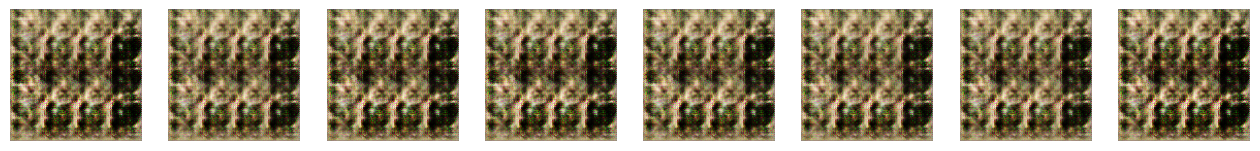

```
round  1 | loss 0.4743 | gate acc 0.5000 | branches 2  <- GREW
round  2 | loss 0.4415 | gate acc 0.5000 | branches 3  <- GREW
round  3 | loss 0.4232 | gate acc 0.5065 | branches 4  <- GREW
round  4 | loss 0.4104 | gate acc 0.5000 | branches 5  <- GREW
round  5 | loss 0.4037 | gate acc 0.5000 | branches 5
round  6 | loss 0.3979 | gate acc 0.5104 | branches 5
stopping: branch cap reached, gate quiet 2 rounds
branches: 5 | buffer: 3840
```

**Diagnosis:** only the **mode collapse** is attributed to the DCGAN. The rest of this run (gate stuck at 0.5, a branch growing every round, loss near 0.47 consistent with "blob = fake, everything else = real") was also shaped by the label bug, so it cannot be read as evidence about the method. **Fix:** the DCGAN was replaced by `PGDAdversary`.

In [ ]:
# ❌ HISTORICAL — the failed run 3 configuration, kept as a record.
# Uses get_loader('train') (label bug) and the old adversarial_train signature (no gate_reals),
# so it will NOT run against the current train_loop.py.
if RERUN_FAILED_EXPERIMENTS:
    import matplotlib.pyplot as plt
    gen_a = LiveGenerator('/content/data/train/fake', device=dev)
    hardened = Detector(Backbone()).to(dev)
    buf = ReplayBuffer()
    hist = adversarial_train(hardened, gen_a,
                             get_loader('train', augment=False, batch_size=32),
                             buf, max_rounds=10, steps_per_round=400)
    with torch.no_grad():
        s = (gen_a.G.sample(8, dev) + 1) / 2
    fig, ax = plt.subplots(1, 8, figsize=(16, 2))
    for i in range(8):
        ax[i].imshow(s[i].permute(1, 2, 0).cpu().clamp(0, 1)); ax[i].axis('off')
    plt.show()
else:
    print('skipped: recorded result is in the markdown above')

skipped: recorded result is in the markdown above


### 🐞 The label bug (found while writing the PGD adversary)

The loop's "real" side drew images from `get_loader('train')`, which returns **real and fake images together**. Every image it supplied was labelled real, so about half of each real batch was ProGAN fakes with the wrong label. Runs 2 and 3 and the control test above were affected.

**Fix:** `real_loader(split)` in `train_loop.py` loads the `real/` folder only, and the gate now reads held-out `val2`. **Not affected:** `train_baseline`, which reads the labels correctly, so the baseline and its numbers are valid.

### ❌ Failed run 4 — PGD from untrained weights (smoke test)

```
round  1 | stage 1 | loss 0.6990 | gate acc 0.3073 | branches 2  <- GREW
round  2 | stage 1 | loss 0.6984 | gate acc 0.5000 | branches 3  <- GREW
```

**Diagnosis:** a loss of 0.699 is ln 2: the model was still guessing. The gate failed because the model had learned nothing yet, not because the adversary found a weakness, so branches grew on ignorance. (A gate below 0.5 is expected here: PGD easily flips an untrained model's answers.) **Fix:** start adversarial training from the baseline's weights. That also gives a clean before/after comparison.

In [ ]:
# ❌ FAILED CONFIGURATION (run 4) — reproducible with the current code.
# Untrained head (ImageNet backbone only), default budget eps = (2, 4, 6, 8)/255, 2 tiny rounds.
if RERUN_FAILED_EXPERIMENTS:
    adv_f4 = PGDAdversary('/content/data/train/fake', '/content/data/val2/fake', device=dev)
    probe = Detector(Backbone()).to(dev)                 # NOT started from the baseline
    adversarial_train(probe, adv_f4, real_loader('train', augment=True),
                      ReplayBuffer(cap_per_round=300),
                      gate_reals=real_loader('val2', augment=False),
                      max_rounds=2, steps_per_round=50)
else:
    print('skipped: recorded result is in the markdown above')

skipped: recorded result is in the markdown above


### ❌ Failed run 5 — PGD from the baseline at ε = 2/255 (smoke test)

```
round  1 | stage 1 | loss 1.1608 | gate acc 0.4909 | branches 2  <- GREW
round  2 | stage 1 | loss 0.6930 | gate acc 0.4362 | branches 3  <- GREW
```

**Diagnosis:** round 2's loss of exactly 0.6930 (ln 2) means the detector collapsed to answering 0.5 for every image. The calibration in 5.6 shows why: the baseline already scores **0.000** at 2/255, so the first stage asked for robustness ten times beyond anything it had. **Fix:** set the budget from the measured robustness curve, starting at 0.125/255.

In [ ]:
# ❌ FAILED CONFIGURATION (run 5) — reproducible with the current code.
# Started from the baseline, but with the default budget eps = (2, 4, 6, 8)/255, 2 tiny rounds.
if RERUN_FAILED_EXPERIMENTS:
    adv_f5 = PGDAdversary('/content/data/train/fake', '/content/data/val2/fake', device=dev)
    probe = Detector(Backbone()).to(dev)
    probe.load_state_dict(torch.load(f'{P}/baseline.pt'))
    adversarial_train(probe, adv_f5, real_loader('train', augment=True),
                      ReplayBuffer(cap_per_round=300),
                      gate_reals=real_loader('val2', augment=False),
                      max_rounds=2, steps_per_round=50)
else:
    print('skipped: recorded result is in the markdown above')

skipped: recorded result is in the markdown above


### 5.6 Calibrating the attack budget

Baseline accuracy on `val2` when **every** image is perturbed by PGD at budget ε. It fixed the curriculum used in 5.7.

**Result:** the baseline is already below chance at 0.25/255, a quarter of one 8-bit brightness level per pixel, and is fooled every time from 2/255. Stage 1 was therefore set to 0.125/255, between its clean 0.846 and its 0.379 at 0.25/255, with each later stage doubling the budget (0.25, 0.5, 1). Perturbations below 1/255 exist only in floating point and vanish if the image is saved at 8 bits, so the early stages are a training signal, not a realistic attack.

In [ ]:
for e in [0, 0.25, 0.5, 1, 2, 4]:
    a = PGDAdversary('/content/data/train/fake', '/content/data/val2/fake',
                     eps_schedule=(e,), adv_frac=1.0, device=dev)
    a.attach(baseline)
    acc = gate_accuracy(baseline, a, real_loader('val2'), device=dev)
    print(f'eps {e}/255: baseline acc {acc:.3f}')

eps 0/255: baseline acc 0.846
eps 0.25/255: baseline acc 0.380
eps 0.5/255: baseline acc 0.082
eps 1/255: baseline acc 0.004
eps 2/255: baseline acc 0.000
eps 4/255: baseline acc 0.000


### 5.7 Final hardening run ✅ → `hardened.pt`

Starts from the baseline's weights and uses the calibrated curriculum (ε = 0.125, 0.25, 0.5, 1 per 255), the `val2` gate and the 0.70 threshold. Set `SMOKE = True` for 2 tiny rounds as a crash check. The smoke test before the full run passed:

```
round  1 | stage 1 | loss 0.2514 | gate acc 0.7109 | branches 1
round  2 | stage 2 | loss 0.4017 | gate acc 0.6419 | branches 2  <- GREW
```

**How to read the full log below.** The gate passed at stage 1, so the adversary advanced; it failed at stage 2, so a branch grew; it recovered and advanced again. Stage 3 (0.5/255) was the limit: three branches grew in a row, stage 4 was never reached, and training stopped with all 5 branch slots full. At stage 3 training loss fell from 0.25 to 0.08 while the held-out gate stayed near 0.64, a sign of overfitting to the training perturbations. The model is saved after every round, and the replay buffer is saved at the end.

In [4]:
import importlib, generator_module, train_loop
importlib.reload(generator_module); importlib.reload(train_loop)
from generator_module import PGDAdversary
from train_loop import (ReplayBuffer, real_loader, gate_accuracy,
                        adversarial_train, save_detector, load_detector)

SMOKE = False        # True first: 2 tiny rounds (~3–5 min) to catch errors
HARD_CKPT = '/content/drive/MyDrive/AI project/hardened.pt'

if os.path.exists(HARD_CKPT) and not RETRAIN and not SMOKE:
    hardened = load_detector(HARD_CKPT, dev)
    print('hardened.pt exists, loading it (set RETRAIN = True in Setup to retrain); recorded log below')
else:
    adv = PGDAdversary('/content/data/train/fake', '/content/data/val2/fake',
                       eps_schedule=(0.125, 0.25, 0.5, 1), device=dev)
    hardened = Detector(Backbone()).to(dev)
    hardened.load_state_dict(torch.load('/content/drive/MyDrive/AI project/baseline.pt'))  # start from the baseline
    buf = ReplayBuffer(cap_per_round=300)

    hist = adversarial_train(
        hardened, adv,
        real_loader('train', augment=True),
        buf,
        gate_reals=real_loader('val2', augment=False),
        max_rounds=2 if SMOKE else 10,
        steps_per_round=50 if SMOKE else 300,
        ckpt_path=None if SMOKE else HARD_CKPT,
    )

    if not SMOKE:
        torch.save(buf.state_dict(), '/content/drive/MyDrive/AI project/replay_buffer.pt')

hardened.pt exists, loading it (set RETRAIN = True in Setup to retrain); recorded log below


# Module 6 — Deployment and post-deployment updates

After training, the model is **deployed**: the backbone and every branch are frozen permanently. When a new family of fakes appears (here, Stable Diffusion), one branch is added and only that branch and the fusion head train, while replayed old fakes keep the fusion head from forgetting.

`deploy_module.py`:
- `make_split` — splits `poolB_sd` into `poolB_sd_upd` (1,000 per class, used to train the update) and `poolB_sd_test` (500 per class, held out). The fixed seed gives the same split every session.
- `folder_loader` — one class from one split.
- `deploy` — freezes the backbone and all branches.
- `frozen_snapshot` — backbone features and every branch's output on a fixed batch; compared before and after an update to prove the frozen parts never changed.
- `incremental_update` — raises the branch cap if needed, adds one branch, trains it plus the fusion head for 400 steps. Each batch holds 16 new + 16 old reals against 24 new + 8 replayed old fakes. `distill = λ > 0` adds **Learning without Forgetting** (Li & Hoiem, 2017): on old data, the model's outputs are held close to a frozen copy of the pre-update model.

In [ ]:
%%writefile "/content/drive/MyDrive/AI project/deploy_module.py"
import random, sys
import torch
import torch.nn as nn
from pathlib import Path
from torch.utils.data import DataLoader

sys.path.append('/content/drive/MyDrive/AI project')
from data_module import AIGIDataset, DST


def make_split(src, dst_a, dst_b, n_a, n_b, seed=0):
    """Deterministic split of a pool into two disjoint folders (symlinks, no copying).
    Same seed -> same split every session."""
    src, dst_a, dst_b = Path(src), Path(dst_a), Path(dst_b)
    for lab in ['real', 'fake']:
        files = sorted((src / lab).glob('*.png'))
        random.Random(seed).shuffle(files)
        for d, chunk in [(dst_a, files[:n_a]), (dst_b, files[n_a:n_a + n_b])]:
            (d / lab).mkdir(parents=True, exist_ok=True)
            for f in chunk:
                link = d / lab / f.name
                if not link.exists():
                    link.symlink_to(f)
        print(f'{lab}: {len(list((dst_a/lab).iterdir()))} -> {dst_a.name}, '
              f'{len(list((dst_b/lab).iterdir()))} -> {dst_b.name}')


def folder_loader(split, lab, augment=True, batch_size=32, workers=2):
    """One class only (lab = 'real' or 'fake')."""
    ds = AIGIDataset(DST / split / lab, 0 if lab == 'real' else 1, augment)
    return DataLoader(ds, batch_size=batch_size, shuffle=True,
                      num_workers=workers, pin_memory=True, drop_last=True)


def deploy(model):
    """Lock the backbone permanently and freeze every existing branch."""
    model.backbone.freeze()
    for b in model.bank.branches:
        b.freeze()
    model.eval()


@torch.no_grad()
def frozen_snapshot(model, x):
    """Backbone features + every branch's output on a fixed batch.
    Compared before/after an update to prove frozen parts never changed."""
    model.eval()
    f = model.backbone(x)
    return f.clone(), [b(f).clone() for b in model.bank.branches]


def incremental_update(model, new_reals, new_fakes, old_reals, buffer,
                       steps=400, lr=1e-3, replay_frac=0.25, device='cuda',
                       update_id='update1', distill=0.0, T=2.0):
    """Post-deployment update: add ONE branch, train only it + the fusion head.
    distill > 0 adds Learning without Forgetting (Li & Hoiem, 2017): on OLD data
    (old reals + replayed fakes), the updated model's output is held close to the
    pre-update model's output. distill=0 is the plain update, unchanged."""
    import copy
    import torch.nn.functional as F

    teacher = None
    if distill > 0:
        teacher = copy.deepcopy(model).eval()   # snapshot of the model BEFORE the update
        for p in teacher.parameters():
            p.requires_grad = False

    model.bank.cap = max(model.bank.cap, len(model.bank.branches) + 1)  # free a slot
    if not model.grow():
        raise RuntimeError('could not add a branch')
    crit = nn.BCEWithLogitsLoss()
    opt = torch.optim.Adam(model.trainable_parameters(), lr=lr)

    loaders = {'nr': new_reals, 'nf': new_fakes, 'or': old_reals}
    its = {k: iter(v) for k, v in loaders.items()}

    def nxt(k):
        try:
            return next(its[k])[0]
        except StopIteration:
            its[k] = iter(loaders[k])
            return next(its[k])[0]

    for i in range(steps):
        r_new, r_old = nxt('nr').to(device), nxt('or').to(device)   # 16 new + 16 old reals
        f_new = nxt('nf').to(device)                                 # 32 new fakes
        n_rep = int(len(f_new) * replay_frac)
        f_old = buffer.sample(n_rep, device=device)                  # 8 replayed old fakes
        f_new = f_new[:len(f_new) - n_rep]                           # keep 24 new fakes
        if f_old is None:
            f_old = f_new[:0]

        x = torch.cat([r_new, r_old, f_new, f_old])
        y = torch.cat([torch.zeros(len(r_new) + len(r_old)),
                       torch.ones(len(f_new) + len(f_old))]).to(device)

        model.train()            # frozen backbone/branches stay in eval via their overrides
        opt.zero_grad()
        logits = model(x)
        loss_task = crit(logits, y)
        loss = loss_task

        if teacher is not None:
            x_old = torch.cat([r_old, f_old])
            with torch.no_grad():
                t_logits = teacher(x_old)
            s_logits = torch.cat([logits[len(r_new):len(r_new) + len(r_old)],
                                  logits[len(x) - len(f_old):]])
            loss_kd = F.binary_cross_entropy_with_logits(
                s_logits / T, torch.sigmoid(t_logits / T)) * T * T
            loss = loss_task + distill * loss_kd

        loss.backward()
        opt.step()

        if i % 20 == 0:
            buffer.add(f_new, update_id)                             # new family joins the buffer
        if (i + 1) % 100 == 0:
            msg = f'step {i+1:4d} | task loss {loss_task.item():.4f}'
            if teacher is not None:
                msg += f' | distill loss {loss_kd.item():.4f}'
            print(msg)
    model.eval()

Overwriting /content/drive/MyDrive/AI project/deploy_module.py


### 6.1 Plain update (λ = 0) → `hardened_updated.pt`

Deploy, measure, update, measure again. Training filled all 5 branch slots, so the cap is raised to 6 for the update.

**Result (run 2, shown below):** Stable Diffusion AUROC 0.405 → 0.809, Midjourney (never trained on) 0.461 → 0.651. The cost is forgetting: ProGAN accuracy 0.814 → 0.728. Both frozen-part checks print `True`, and the update trained 98,625 of 11,644,737 parameters (0.85%). Real-image accuracy on Stable Diffusion fell to about 0.46: the updated model leans toward "fake", so AUROC is the reliable comparison here.

**Run 1 (an earlier session, same code)**, kept to estimate run-to-run noise: ProGAN acc 0.729 / AUROC 0.822, Stable Diffusion AUROC 0.777, Midjourney AUROC 0.639. The two runs differ by about 0.03 AUROC on Stable Diffusion and under 0.01 on ProGAN.

In [ ]:
import os, importlib, deploy_module
importlib.reload(deploy_module)
from deploy_module import make_split, folder_loader, deploy, frozen_snapshot, incremental_update
from train_loop import ReplayBuffer, load_detector, save_detector
from train_utils import full_eval
from data_module import get_loader

P = '/content/drive/MyDrive/AI project'

if RETRAIN or not os.path.exists(f'{P}/hardened_updated.pt'):
    # 1. split poolB_sd: 1000/class to train the update, 500/class held out for testing
    make_split('/content/data/poolB_sd', '/content/data/poolB_sd_upd',
               '/content/data/poolB_sd_test', 1000, 500)

    # 2. load the hardened model + replay buffer, then deploy (freeze everything)
    model = load_detector(f'{P}/hardened.pt', dev)
    buf = ReplayBuffer()
    buf.load_state_dict(torch.load(f'{P}/replay_buffer.pt'))
    deploy(model)
    print('branches:', len(model.bank.branches), '| replay buffer:', len(buf))

    # 3. BEFORE the update
    xs, _ = next(iter(get_loader('val', augment=False, batch_size=16, shuffle=False)))
    xs = xs.to(dev)
    f_before, outs_before = frozen_snapshot(model, xs)

    print('\n=== before update ===')
    full_eval(baseline, get_loader('poolB_sd_test', augment=False), dev, tag='baseline poolB_sd_test')
    for pool in ['val', 'poolB_sd_test', 'poolB_mj']:
        full_eval(model, get_loader(pool, augment=False), dev, tag=pool)

    # 4. the update: one new branch, trained on the new family + replay
    print('\n=== updating ===')
    incremental_update(model,
        new_reals=folder_loader('poolB_sd_upd', 'real', batch_size=16),
        new_fakes=folder_loader('poolB_sd_upd', 'fake', batch_size=32),
        old_reals=folder_loader('train', 'real', batch_size=16),
        buffer=buf, steps=400, device=dev)

    # 5. AFTER the update
    print('\n=== after update ===')
    for pool in ['val', 'poolB_sd_test', 'poolB_mj']:
        full_eval(model, get_loader(pool, augment=False), dev, tag=pool)

    f_after, outs_after = frozen_snapshot(model, xs)
    print('\nbackbone unchanged:     ', torch.equal(f_before, f_after))
    print('old branches unchanged: ', all(torch.equal(a, b) for a, b in zip(outs_before, outs_after)))
    n_train = sum(p.numel() for p in model.trainable_parameters())
    n_total = sum(p.numel() for p in model.parameters())
    print(f'update trained {n_train:,} of {n_total:,} parameters ({100*n_train/n_total:.2f}%)')

    save_detector(model, f'{P}/hardened_updated.pt')
    torch.save(buf.state_dict(), f'{P}/replay_buffer_updated.pt')   # original buffer kept as-is
else:
    print('hardened_updated.pt exists, skipped (set RETRAIN = True in Setup to redo); recorded output below')

hardened_updated.pt exists, skipped (set RETRAIN = True in Setup to redo); recorded output below


### 6.2 Update with the forgetting fix (λ = 1) → `hardened_updated_lwf.pt`

The same starting model, the same **original** replay buffer and the same 400 steps; the only change is the distillation penalty.

**Result:** ProGAN accuracy 0.784 (forgetting cut from 8.6 to 3.0 points) and Stable Diffusion AUROC 0.719: still a large gain, but smaller than the plain update's. The distill loss stays around 0.3–0.6 rather than falling toward 0, which is expected: it compares against soft probabilities, so it has a floor above zero.

In [ ]:
import importlib, deploy_module
importlib.reload(deploy_module)
from deploy_module import make_split, folder_loader, deploy, frozen_snapshot, incremental_update
from train_loop import ReplayBuffer, load_detector, save_detector
from train_utils import full_eval
from data_module import get_loader

P = '/content/drive/MyDrive/AI project'

if RETRAIN or not os.path.exists(f'{P}/hardened_updated_lwf.pt'):
    make_split('/content/data/poolB_sd', '/content/data/poolB_sd_upd',
               '/content/data/poolB_sd_test', 1000, 500)        # no-op if the split exists

    # same starting point as the plain update
    model_lwf = load_detector(f'{P}/hardened.pt', dev)
    buf_lwf = ReplayBuffer()
    buf_lwf.load_state_dict(torch.load(f'{P}/replay_buffer.pt'))   # ORIGINAL buffer
    deploy(model_lwf)

    xs, _ = next(iter(get_loader('val', augment=False, batch_size=16, shuffle=False)))
    xs = xs.to(dev)
    f_before, outs_before = frozen_snapshot(model_lwf, xs)

    print('=== updating WITH forgetting fix ===')
    incremental_update(model_lwf,
        new_reals=folder_loader('poolB_sd_upd', 'real', batch_size=16),
        new_fakes=folder_loader('poolB_sd_upd', 'fake', batch_size=32),
        old_reals=folder_loader('train', 'real', batch_size=16),
        buffer=buf_lwf, steps=400, device=dev, distill=1.0)

    print('\n=== after update WITH forgetting fix ===')
    for pool in ['val', 'poolB_sd_test', 'poolB_mj']:
        full_eval(model_lwf, get_loader(pool, augment=False), dev, tag=pool)

    f_after, outs_after = frozen_snapshot(model_lwf, xs)
    print('\nbackbone unchanged:     ', torch.equal(f_before, f_after))
    print('old branches unchanged: ', all(torch.equal(a, b) for a, b in zip(outs_before, outs_after)))

    save_detector(model_lwf, f'{P}/hardened_updated_lwf.pt')
else:
    print('hardened_updated_lwf.pt exists, skipped (set RETRAIN = True in Setup to redo); recorded output below')

hardened_updated_lwf.pt exists, skipped (set RETRAIN = True in Setup to redo); recorded output below


### 6.3 Mapping the trade-off (λ = 0.5 and 2)

Two more strengths, same protocol. These models were evaluated but **not saved**, so they do not appear in the Pool C test.

**Result:** as λ rises, ProGAN retention improves at every step and Stable Diffusion learning falls at every step. This is the stability–plasticity trade-off; at λ = 2 forgetting nearly disappears (ProGAN AUROC 0.886 against 0.894 before the update).

In [ ]:
# runs only when RETRAIN = True (no checkpoints are saved here)
if RETRAIN:
    for lam in [0.5, 2.0]:
        m = load_detector(f'{P}/hardened.pt', dev)
        b = ReplayBuffer(); b.load_state_dict(torch.load(f'{P}/replay_buffer.pt'))
        deploy(m)
        incremental_update(m,
            new_reals=folder_loader('poolB_sd_upd', 'real', batch_size=16),
            new_fakes=folder_loader('poolB_sd_upd', 'fake', batch_size=32),
            old_reals=folder_loader('train', 'real', batch_size=16),
            buffer=b, steps=400, device=dev, distill=lam)
        print(f'\n--- distill = {lam} ---')
        for pool in ['val', 'poolB_sd_test', 'poolB_mj']:
            full_eval(m, get_loader(pool, augment=False), dev, tag=pool)
else:
    print('skipped (set RETRAIN = True in Setup to redo); recorded output below')

skipped (set RETRAIN = True in Setup to redo); recorded output below


### 6.4 Trade-off figure → `fig_lwf_tradeoff.png`

AUROC values copied from the outputs above (λ = 0 is the mean of the two plain-update runs):

| λ | ProGAN acc | ProGAN AUROC | Stable Diffusion AUROC | Midjourney AUROC |
| --- | --- | --- | --- | --- |
| before update | 0.814 | 0.894 | 0.405 | 0.461 |
| 0 (plain) | 0.728 | 0.819 | 0.793 | 0.645 |
| 0.5 | 0.774 | 0.855 | 0.746 | 0.617 |
| 1 | 0.784 | 0.873 | 0.719 | 0.591 |
| 2 | 0.805 | 0.886 | 0.658 | 0.566 |

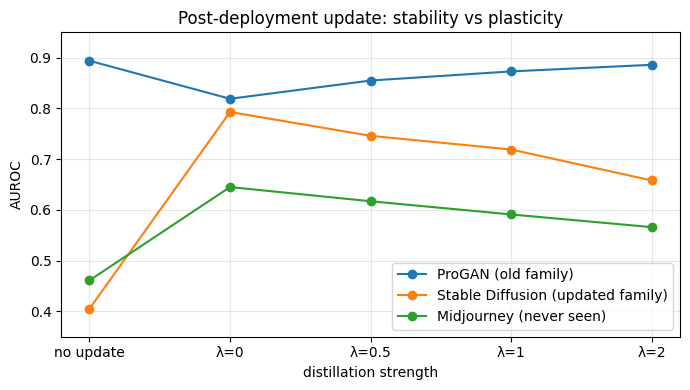

In [ ]:
import matplotlib.pyplot as plt
labels = ['no update', 'λ=0', 'λ=0.5', 'λ=1', 'λ=2']
plt.figure(figsize=(7, 4))
plt.plot(labels, [0.894, 0.819, 0.855, 0.873, 0.886], 'o-', label='ProGAN (old family)')
plt.plot(labels, [0.405, 0.793, 0.746, 0.719, 0.658], 'o-', label='Stable Diffusion (updated family)')
plt.plot(labels, [0.461, 0.645, 0.617, 0.591, 0.566], 'o-', label='Midjourney (never seen)')
plt.ylabel('AUROC'); plt.xlabel('distillation strength'); plt.ylim(0.35, 0.95)
plt.title('Post-deployment update: stability vs plasticity')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig('/content/drive/MyDrive/AI project/fig_lwf_tradeoff.png', dpi=150)
plt.show()

# Module 7 — Evaluation

1. **7.1** Hardened vs baseline: unseen diffusion pools and robustness.
2. **7.2** Growth ablation: does growing branches during training help?
3. **7.3** The sealed Pool C test, run once.
4. **7.4** Results summary.

Measurement noise: each `gate_accuracy` reading uses 768 random images and random attack starts, so readings of the same model vary by about ±0.03 (the hardened model scores 0.818 at ε = 0 in 7.1 and 0.786 in 7.2). `full_eval` uses the whole pool and is deterministic.

### 7.1 Hardened vs baseline

**Unseen diffusion:** no improvement. On Stable Diffusion the hardened model catches slightly more fakes (12.5% vs 7.5%) but misclassifies more real images, which is a threshold shift; its AUROC fell (0.461 → 0.407).

**Robustness:** a large improvement. At ε = 0.5/255 accuracy rose from 0.079 to 0.497, and at 1/255 from 0.003 to 0.242, at a cost of 3.5 points of clean accuracy (0.853 → 0.818), the usual robustness–accuracy trade-off.

In [ ]:
hardened = load_detector(f'{P}/hardened.pt', dev)   # so this cell runs after Setup + Quick start alone

print('=== unseen generators ===')
for name, model in [('baseline', baseline), ('hardened', hardened)]:
    print(f'--- {name} ---')
    for pool in ['val', 'poolB_sd', 'poolB_mj']:
        full_eval(model, get_loader(pool, augment=False), dev, tag=pool)

print('\n=== robustness curve (every image perturbed) ===')
for name, model in [('baseline', baseline), ('hardened', hardened)]:
    for e in [0, 0.25, 0.5, 1, 2]:
        a = PGDAdversary('/content/data/train/fake', '/content/data/val2/fake',
                         eps_schedule=(e,), adv_frac=1.0, device=dev)
        a.attach(model)
        print(f'{name:9s} eps {e}/255: acc {gate_accuracy(model, a, real_loader("val2"), device=dev):.3f}')

=== unseen generators ===
--- baseline ---
val: acc 0.8612 | real 0.8600 | fake 0.8625 | AUROC 0.9339
poolB_sd: acc 0.4877 | real 0.9007 | fake 0.0747 | AUROC 0.4612
poolB_mj: acc 0.4980 | real 0.8960 | fake 0.1000 | AUROC 0.4803
--- hardened ---
val: acc 0.8138 | real 0.8525 | fake 0.7750 | AUROC 0.8940
poolB_sd: acc 0.4773 | real 0.8293 | fake 0.1253 | AUROC 0.4068
poolB_mj: acc 0.4870 | real 0.8200 | fake 0.1540 | AUROC 0.4611

=== robustness curve (every image perturbed) ===
baseline  eps 0/255: acc 0.857
baseline  eps 0.25/255: acc 0.327
baseline  eps 0.5/255: acc 0.055
baseline  eps 1/255: acc 0.008
baseline  eps 2/255: acc 0.000
hardened  eps 0/255: acc 0.811
hardened  eps 0.25/255: acc 0.673
hardened  eps 0.5/255: acc 0.501
hardened  eps 1/255: acc 0.206
hardened  eps 2/255: acc 0.021


### 7.2 Growth ablation → `nogrow.pt`

Same starting weights (the baseline), the same adversary stage schedule (1, 2, 2, 3, 3, 3, 3, 3) and the same 3,600 gradient steps as the hardened model (8 × 300 sparring + 4 × 300 branch training), but **growth switched off: one branch**. Only the branch count differs.

In [ ]:
from generator_module import PGDAdversary
from train_loop import ReplayBuffer, real_loader, gate_accuracy, spar, save_detector, load_detector
from model_module import Detector, Backbone
P = '/content/drive/MyDrive/AI project'

if os.path.exists(f'{P}/nogrow.pt') and not RETRAIN:
    nogrow = load_detector(f'{P}/nogrow.pt', dev)
    print('nogrow.pt exists, loading it (set RETRAIN = True in Setup to retrain); recorded log below')
else:
    SCHEDULE = [1, 2, 2, 3, 3, 3, 3, 3]   # the stages the grown model actually went through
    STEPS = 450                            # 8 x 450 = 3,600 = hardened's 2,400 sparring + 4 x 300 branch training

    nogrow = Detector(Backbone()).to(dev)
    nogrow.load_state_dict(torch.load(f'{P}/baseline.pt'))          # same starting point
    adv = PGDAdversary('/content/data/train/fake', '/content/data/val2/fake',
                       eps_schedule=(0.125, 0.25, 0.5, 1), device=dev)
    adv.attach(nogrow)
    train_reals = real_loader('train', augment=True)
    gate_reals = real_loader('val2', augment=False)
    scratch = ReplayBuffer()               # spar() needs one; not used for anything here

    for rnd, stage in enumerate(SCHEDULE, 1):
        adv.stage = stage
        opt = torch.optim.Adam([
            {'params': nogrow.backbone.parameters(),                'lr': 1e-4},
            {'params': nogrow.bank.trainable_branch().parameters(), 'lr': 1e-3},
            {'params': nogrow.fusion.parameters(),                  'lr': 1e-3},
        ])
        loss = spar(nogrow, adv, train_reals, opt, STEPS, scratch, rnd, dev)
        acc = gate_accuracy(nogrow, adv, gate_reals, device=dev)
        print(f'round {rnd} | stage {stage} | loss {loss:.4f} | gate acc {acc:.4f} | branches 1')

    save_detector(nogrow, f'{P}/nogrow.pt')

nogrow.pt exists, loading it (set RETRAIN = True in Setup to retrain); recorded log below


**Side by side. Result:** a tie. Every robustness gap is under 0.04 and they run in both directions; clean and diffusion AUROCs match to within 0.013. The training logs also ended level (gate 0.643 vs 0.650). Growth during training added no measurable benefit. This comparison cannot separate frozen specialist branches from simply having more parameters, a caveat for the report.

In [ ]:
hardened = load_detector(f'{P}/hardened.pt', dev)
nogrow   = load_detector(f'{P}/nogrow.pt', dev)
models = [('hardened (5 branches)', hardened), ('no growth (1 branch)', nogrow)]

print('=== clean + unseen generators ===')
for name, m in models:
    print(f'--- {name} ---')
    for pool in ['val', 'poolB_sd', 'poolB_mj']:
        full_eval(m, get_loader(pool, augment=False), dev, tag=pool)

print('\n=== robustness curve (every image perturbed) ===')
for name, m in models:
    for e in [0, 0.25, 0.5, 1, 2]:
        a = PGDAdversary('/content/data/train/fake', '/content/data/val2/fake',
                         eps_schedule=(e,), adv_frac=1.0, device=dev)
        a.attach(m)
        print(f'{name:22s} eps {e}/255: acc {gate_accuracy(m, a, real_loader("val2"), device=dev):.3f}')

=== clean + unseen generators ===
--- hardened (5 branches) ---
val: acc 0.8138 | real 0.8525 | fake 0.7750 | AUROC 0.8940
poolB_sd: acc 0.4773 | real 0.8293 | fake 0.1253 | AUROC 0.4068
poolB_mj: acc 0.4870 | real 0.8200 | fake 0.1540 | AUROC 0.4611
--- no growth (1 branch) ---
val: acc 0.8163 | real 0.7800 | fake 0.8525 | AUROC 0.8898
poolB_sd: acc 0.4660 | real 0.8067 | fake 0.1253 | AUROC 0.3943
poolB_mj: acc 0.4920 | real 0.8080 | fake 0.1760 | AUROC 0.4615

=== robustness curve (every image perturbed) ===
hardened (5 branches)  eps 0/255: acc 0.792
hardened (5 branches)  eps 0.25/255: acc 0.650
hardened (5 branches)  eps 0.5/255: acc 0.516
hardened (5 branches)  eps 1/255: acc 0.212
hardened (5 branches)  eps 2/255: acc 0.027
no growth (1 branch)   eps 0/255: acc 0.801
no growth (1 branch)   eps 0.25/255: acc 0.647
no growth (1 branch)   eps 0.5/255: acc 0.514
no growth (1 branch)   eps 1/255: acc 0.216
no growth (1 branch)   eps 2/255: acc 0.023


### 7.3 Pool C — the sealed final test (run once)

Pool C was never used for any decision; this cell ran once, after everything else was final. **StyleGAN2** shares the training content (LSUN cats and horses), so it isolates the generator; **BigGAN** changes both the generator and the content (ImageNet).

**Result:**
- Both adversarially trained models beat the baseline on StyleGAN2 by 0.07–0.08 AUROC (0.594 → 0.668 / 0.676). Hardening generalises to an unseen GAN, though not to diffusion (7.1).
- Hardened and no-growth tie again (0.668 vs 0.676).
- BigGAN defeats every model (AUROC 0.46–0.53, within noise).
- Updates hurt StyleGAN2 (0.668 → 0.533 plain, 0.585 with λ = 1): forgetting reaches related unseen GAN families too, and distillation only partly protects them.

In [ ]:
import importlib, train_loop
importlib.reload(train_loop)
from train_loop import load_detector
from model_module import Detector, Backbone
from train_utils import full_eval
from data_module import get_loader
P = '/content/drive/MyDrive/AI project'

def load_baseline():
    m = Detector(Backbone()).to(dev)
    m.load_state_dict(torch.load(f'{P}/baseline.pt'))
    return m.eval()

models = [
    ('baseline',          load_baseline()),
    ('hardened',          load_detector(f'{P}/hardened.pt', dev)),
    ('no growth',         load_detector(f'{P}/nogrow.pt', dev)),
    ('updated, plain',    load_detector(f'{P}/hardened_updated.pt', dev)),
    ('updated, lambda=1', load_detector(f'{P}/hardened_updated_lwf.pt', dev)),
]

print('=== POOL C: sealed final test (run once) ===')
for name, m in models:
    print(f'--- {name} ---')
    for pool in ['poolC_stylegan2', 'poolC_biggan']:
        full_eval(m, get_loader(pool, augment=False), dev, tag=pool)

=== POOL C: sealed final test (run once) ===
--- baseline ---
poolC_stylegan2: acc 0.5475 | real 0.8450 | fake 0.2500 | AUROC 0.5935
poolC_biggan: acc 0.4885 | real 0.8870 | fake 0.0900 | AUROC 0.5191
--- hardened ---
poolC_stylegan2: acc 0.6000 | real 0.8430 | fake 0.3570 | AUROC 0.6677
poolC_biggan: acc 0.4895 | real 0.8390 | fake 0.1400 | AUROC 0.4877
--- no growth ---
poolC_stylegan2: acc 0.6225 | real 0.7500 | fake 0.4950 | AUROC 0.6763
poolC_biggan: acc 0.4790 | real 0.7860 | fake 0.1720 | AUROC 0.4615
--- updated, plain ---
poolC_stylegan2: acc 0.5220 | real 0.6890 | fake 0.3550 | AUROC 0.5325
poolC_biggan: acc 0.5265 | real 0.4830 | fake 0.5700 | AUROC 0.5284
--- updated, lambda=1 ---
poolC_stylegan2: acc 0.5550 | real 0.7300 | fake 0.3800 | AUROC 0.5849
poolC_biggan: acc 0.5160 | real 0.5390 | fake 0.4930 | AUROC 0.5051


### 7.4 Results summary

| Claim tested | Evidence | Verdict |
| --- | --- | --- |
| Hardening improves robustness | ε = 1/255: 0.003 → 0.242 (7.1) | ✅ Supported |
| Hardening generalises to unseen generators | StyleGAN2 AUROC 0.594 → 0.668 (7.3); diffusion 0.461 → 0.407 (7.1); BigGAN at chance | ⚠️ Same family only (GAN → GAN) |
| Growing branches during training helps | Ties with the one-branch model in 7.2 and 7.3 | ❌ Not supported: keep branch slots for deployment |
| A post-deployment update learns a new family cheaply | Stable Diffusion AUROC 0.405 → 0.793 (mean of 2 runs) training 0.85% of parameters; Midjourney 0.461 → 0.645 (6.1) | ✅ Supported |
| Frozen parts stay untouched | Backbone and old branches bit-identical after every update (6.1, 6.2) | ✅ Supported |
| Forgetting can be controlled | ProGAN accuracy loss 8.6 → 3.0 (λ = 1) → 0.9 points (λ = 2) (6.4) | ✅ Supported, with a trade-off; unseen GAN families still lose some ground |

**Limitations:** one training run per configuration (noise about ±0.03); small scale (10,000 training images, two LSUN categories, 128×128); no clean extra-training control for the hardened model; Pool B and BigGAN use ImageNet reals while training used LSUN; Path B was not re-run after the label-bug fix.